# 15 · Reasoning and test-time compute

Since 2024 the most capable models have been **reasoning models** (OpenAI o1/o3, DeepSeek-R1, Claude with extended thinking, Gemini thinking, Qwen3): they spend extra tokens thinking before they answer, and the more they think, the better they do on problems with a checkable answer. This notebook takes that idea apart on grade-school math problems (GSM8K), with a local 3B model, and measures every lever:

| lever | what it does | measured here |
|---|---|---|
| **chain of thought** | ask the model to reason step by step before answering | accuracy and tokens vs a direct answer |
| **self-consistency** | sample several reasoning paths and take the majority answer | accuracy as the number of samples grows (maj@k), and the oracle pass@k |
| **best-of-N with a verifier** | a second model scores each candidate and the best one wins | a 7B judge as verifier vs majority voting |
| **a reasoning model** | a model trained (with RL, notebook 14) or distilled to think at length | DeepSeek-R1-Distill 1.5B vs prompting the 3B model |
| **the cost-accuracy trade-off** | all of the above as points on one curve | output tokens per problem vs accuracy |
| **comparative evaluation** | ranking strategies from pairwise outcomes, and the biases of a pairwise judge | Bradley-Terry scores with intervals; position bias of an LLM judge |

Read it **after notebook 14**: GRPO there is how reasoning is trained; here is how it is used and measured.

**Sources.** Stanford CME 295, LLM reasoning; Huyen, *AI Engineering*, ch. 2 (sampling, test-time compute) and ch. 3–4 (comparative evaluation).

## Background: thinking with tokens

### Why chain of thought works

A transformer does a fixed amount of computation per token (notebook 03). A problem that needs several dependent steps, "first compute the eggs left, then their price", cannot be solved in one forward pass if the steps do not fit in the layers. Writing the intermediate steps as tokens turns the generated text into a scratchpad: each new token can attend to the results written before it, so **more tokens buy more serial computation**. Wei et al. (2022) showed that a few worked examples in the prompt (few-shot chain of thought) unlock multi-step reasoning in large models; Kojima et al. (2022) that "Let's think step by step" alone does much of it (zero-shot CoT). A theoretical view: with intermediate steps, transformers can solve problems they provably cannot solve in a single pass (Feng et al., 2023; Merrill and Sabharwal, 2024).

### Spending more compute at inference

Once a model can reason, there are two ways to spend more compute on one problem:

- **Parallel sampling.** Generate $N$ reasoning paths and combine them. **Self-consistency** (Wang et al., 2023) takes the most frequent final answer: different correct paths tend to agree, wrong ones scatter. Its accuracy, **maj@k**, rises with $k$ and saturates. The upper bound is **pass@k**, the chance that *at least one* of $k$ samples is right, which a perfect verifier would reach.
- **Best-of-N with a verifier.** A second model scores each candidate and the highest-scored one is returned. An **outcome reward model** (ORM) scores the final answer (Cobbe et al., 2021, *Training Verifiers*); a **process reward model** (PRM) scores every step (Lightman et al., 2023, *Let's Verify Step by Step*). A verifier is only as good as its discrimination: if it cannot tell right from wrong better than a vote, it adds cost and no accuracy.
- **Sequential refinement.** Revise one answer several times (self-refine, notebook 25's reflection), or force the model to keep thinking (*budget forcing*, s1, Muennighoff et al., 2025).

Snell et al. (2024) showed that for a fixed compute budget, spending it at test time can beat a model several times larger on problems of the right difficulty: test-time compute is a scaling axis of its own.

### Reasoning models

Instead of prompting, reasoning can be **trained**. DeepSeek-R1 (2025) applied large-scale RL with verifiable rewards (GRPO, notebook 14) and got long chains of thought, self-checking and backtracking to emerge; OpenAI's o1 did the same with an undisclosed recipe. The thinking is emitted as tokens (often between `<think>` tags) and paid for like any other output. **Distillation** transfers it cheaply: DeepSeek fine-tuned small Qwen and Llama models on R1's reasoning traces (*R1-Distill*), the 1.5B version of which runs here. Whether such small distilled models reason robustly outside their training distribution is an open question, and we measure it rather than assume it.

### Costs and failure modes

Reasoning is paid in output tokens, which are the slow and expensive ones (notebook 10): ten times the tokens is roughly ten times the latency and the price. Known failure modes: **unfaithful** chains of thought, where the written reasoning is not what produced the answer (Turpin et al., 2023); **overthinking** easy problems; verifiers that are fooled or **reward-hacked**; and answer-extraction errors, which silently turn a right solution into a wrong score.

### Comparing strategies: pairwise evaluation

Many evaluations compare two systems on the same input rather than scoring each in isolation: Chatbot Arena ranks models from millions of human votes between two anonymous answers. The **Bradley-Terry** model turns such outcomes into scores: system $i$ beats system $j$ with probability

$$P(i \succ j) = \frac{e^{\beta_i}}{e^{\beta_i} + e^{\beta_j}}$$

and the $\beta$ are fitted by maximum likelihood (Elo ratings are an online approximation of the same idea). When the judge is an LLM, its known biases must be measured: **position bias** (preferring the first or second answer regardless of content), verbosity bias and self-preference (Zheng et al., 2023, *Judging LLM-as-a-Judge*). The standard defence is to judge every pair in both orders and keep only consistent verdicts.

**Key papers.** Wei et al. (2022), *Chain-of-Thought Prompting*; Kojima et al. (2022), *Large Language Models are Zero-Shot Reasoners*; Wang et al. (2023), *Self-Consistency*; Cobbe et al. (2021), *Training Verifiers to Solve Math Word Problems* (GSM8K); Lightman et al. (2023), *Let's Verify Step by Step*; Snell et al. (2024), *Scaling LLM Test-Time Compute Optimally*; DeepSeek-AI (2025), *DeepSeek-R1*; Muennighoff et al. (2025), *s1: Simple test-time scaling*; Turpin et al. (2023), *Language Models Don't Always Say What They Think*; Zheng et al. (2023), *Judging LLM-as-a-Judge*; Bradley and Terry (1952).

In [1]:
import os, sys, json, time, random
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)                     # so `llm_edu_suite` imports from any notebooks/ sub-folder
import numpy as np
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)

In [2]:
import re, collections, logging, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import datasets; datasets.disable_progress_bars()
from llm_edu_suite.config import get_llm, get_judge_llm, judge_model
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff

N_PROB = 80
gsm = datasets.load_dataset("openai/gsm8k", "main", split="test").shuffle(seed=0).select(range(N_PROB))
QUESTIONS = gsm["question"]
GOLD = [float(a.split("####")[-1].replace(",", "").strip()) for a in gsm["answer"]]

def final_number(text):
    """The last number in the visible answer (after any </think> block). Extraction is part of the evaluation."""
    text = text.split("</think>")[-1].replace("$", "").replace(",", "")
    m = re.findall(r"-?\d+(?:\.\d+)?", text)
    return float(m[-1]) if m else None
def correct(pred, gold):
    return pred is not None and abs(pred - gold) < 1e-6

def generate(llm, prompts, concurrency=4):
    """Run a batch; return texts, output tokens per call and wall time per call (4 requests in flight)."""
    t0 = time.time(); outs = llm.batch(prompts, config={"max_concurrency": concurrency}); dt = time.time() - t0
    toks = [(o.usage_metadata or {}).get("output_tokens", 0) for o in outs]
    return [o.content for o in outs], np.array(toks), dt / len(prompts)

RES = {}       # strategy -> dict(ok: per-problem 0/1, tokens: mean output tokens per problem, secs: wall seconds per problem)
print(f"{N_PROB} GSM8K test problems | e.g. {QUESTIONS[0][:120]}... -> {GOLD[0]:g}")

80 GSM8K test problems | e.g. Carmen has $100, Samantha has $25 more than Carmen, and Daisy has $50 more than Samantha. How much do all three girls ha... -> 400


## 1. Direct answer vs chain of thought

Same model (`qwen2.5:3b`), greedy decoding. **Direct**: "answer with the final number only", 16 tokens allowed. **Chain of thought**: "solve step by step, then give the final answer as a number on the last line".

In [3]:
direct_llm = get_llm(num_predict=16)
cot_llm = get_llm(num_predict=512)
DIRECT = "Answer with the final number only, no words."
COT = "Solve the problem step by step, then give the final answer as a number on the last line."
for name, llm, system in (("direct", direct_llm, DIRECT), ("chain of thought", cot_llm, COT)):
    texts, toks, secs = generate(llm, [[("system", system), ("user", q)] for q in QUESTIONS])
    ok = np.array([correct(final_number(t), g) for t, g in zip(texts, GOLD)], dtype=float)
    RES[name] = dict(ok=ok, tokens=float(toks.mean()), secs=secs)
    if name == "chain of thought": cot_texts = texts
    m, lo, hi = bootstrap_ci(ok)
    print(f"{name:18s} accuracy {m:.1%} [{lo:.1%}, {hi:.1%}] | {toks.mean():5.0f} output tokens per problem | {secs:.2f}s per problem")
print("\nA chain of thought:\n" + cot_texts[0][:600])

direct             accuracy 12.5% [6.2%, 20.0%] |     3 output tokens per problem | 0.18s per problem


chain of thought   accuracy 85.0% [77.5%, 92.5%] |   246 output tokens per problem | 3.79s per problem

A chain of thought:
Step 1: Determine how much Samantha has.
Samantha has $25 more than Carmen. Since Carmen has $100, Samantha has $100 + $25 = $125.

Step 2: Determine how much Daisy has.
Daisy has $50 more than Samantha. Since Samantha has $125, Daisy has $125 + $50 = $175.

Step 3: Calculate the total amount all three girls have combined.
Carmen has $100, Samantha has $125, and Daisy has $175. Combined, they have $100 + $125 + $175 = $400.

The final answer is $400.


**What the numbers say.** The same 3B model goes from **12.5 % to 85.0 %** when it is allowed to write its reasoning, with intervals that do not come close to overlapping. The price is 246 output tokens instead of 3, and 3.79 s instead of 0.18 s per problem. The example shows why it works: each step writes an intermediate result (125, 175) that the next step reads back, which is exactly the serial computation a single forward pass cannot do. Asked for the number alone, the model has to do all of it "in its head", in a fixed number of layers, and mostly fails.

## 2. Self-consistency: sample several paths, vote

Five chains of thought per problem at temperature 0.7. For every $k$ from 1 to 5 we compute **maj@k** (majority vote among the first $k$ samples; ties go to the earliest answer) and **pass@k** (at least one of the $k$ is right: the ceiling a perfect verifier would reach).

k=1: maj@k 80.0% | pass@k 80.0% | ~248 output tokens per problem
k=2: maj@k 80.0% | pass@k 87.5% | ~496 output tokens per problem
k=3: maj@k 83.8% | pass@k 88.8% | ~745 output tokens per problem
k=4: maj@k 83.8% | pass@k 91.2% | ~993 output tokens per problem
k=5: maj@k 85.0% | pass@k 92.5% | ~1241 output tokens per problem

maj@5 - greedy chain of thought: +0.0% [-6.2%, +6.2%]


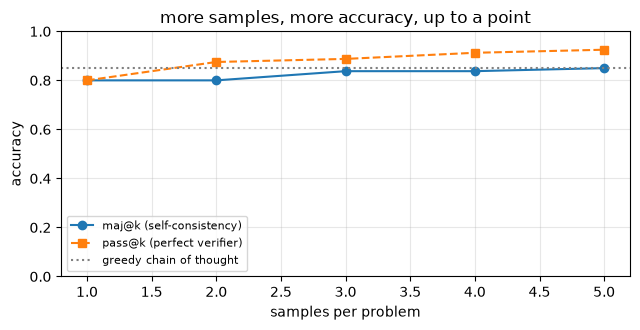

In [4]:
K = 5
sc_llm = get_llm(temperature=0.7, num_predict=512)
prompts = [[("system", COT), ("user", q)] for q in QUESTIONS for _ in range(K)]
texts, toks, secs = generate(sc_llm, prompts)
SAMPLES = [[final_number(texts[p * K + j]) for j in range(K)] for p in range(N_PROB)]
SAMPLE_TEXTS = [[texts[p * K + j] for j in range(K)] for p in range(N_PROB)]
tok_per_sample = float(toks.mean())

def majority(answers):
    valid = [a for a in answers if a is not None]
    if not valid: return None
    counts = collections.Counter(valid); best = max(counts.values())
    return next(a for a in valid if counts[a] == best)            # ties: the earliest answer among the most frequent
maj = {k: np.array([correct(majority(s[:k]), g) for s, g in zip(SAMPLES, GOLD)], dtype=float) for k in range(1, K + 1)}
pas = {k: np.array([any(correct(a, g) for a in s[:k]) for s, g in zip(SAMPLES, GOLD)], dtype=float) for k in range(1, K + 1)}
for k in range(1, K + 1):
    print(f"k={k}: maj@k {maj[k].mean():.1%} | pass@k {pas[k].mean():.1%} | ~{k * tok_per_sample:.0f} output tokens per problem")
RES["self-consistency, 5 samples"] = dict(ok=maj[K], tokens=K * tok_per_sample, secs=K * secs)
d = paired_bootstrap_diff(RES["chain of thought"]["ok"], maj[K])
print(f"\nmaj@5 - greedy chain of thought: {d[0]:+.1%} [{d[1]:+.1%}, {d[2]:+.1%}]")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ks = list(range(1, K + 1))
ax.plot(ks, [maj[k].mean() for k in ks], "o-", label="maj@k (self-consistency)"); ax.plot(ks, [pas[k].mean() for k in ks], "s--", label="pass@k (perfect verifier)")
ax.axhline(RES["chain of thought"]["ok"].mean(), color="gray", ls=":", label="greedy chain of thought")
ax.set_xlabel("samples per problem"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("more samples, more accuracy, up to a point"); plt.tight_layout(); plt.show()

**What the numbers say.** One sample at temperature 0.7 is worse than greedy decoding (80.0 % vs 85.0 %): sampling adds variety, and some of it is error. Voting only wins that back: maj@5 reaches **85.0 %**, the same as greedy chain of thought (difference +0.0 points, 95 % interval [−6.2, +6.2]). It costs five times the tokens, about 1,241 per problem. The ceiling is higher: pass@5 is 92.5 %, so for 6 of the 80 problems a right answer was among the samples, but in the minority. An earlier run of this notebook measured maj@5 at 90.0 %; with 80 problems, a 5-point gain is inside the noise, and this run shows it.

pass@k tells you what a perfect judge could get out of the same samples: 92.5 % with 5 samples, 7.5 points above maj@5. That gap is what a good verifier could win back; when pass@k is far above maj@k, a verifier is worth building, and section 3 tests one.

## 3. Best-of-N with a verifier

Can a second model pick the right sample better than a vote? The judge (`qwen2.5:7b` when pulled, notebook 18) reads each of the five solutions and rates from 1 to 10 how likely its final answer is correct; the highest-rated solution wins, ties broken by majority. It runs on the first 40 problems to keep the cost reasonable, and we compare on the same 40 with majority voting and the pass@5 ceiling.

In [5]:
from pydantic import BaseModel, Field
class Verdict(BaseModel):
    reasoning: str = Field(description="at most two short sentences, plain text, no LaTeX")
    score: int = Field(ge=1, le=10, description="10 = the final answer is certainly correct, 1 = certainly wrong")
# include_raw: a verdict that is cut off or malformed comes back as data (parsed=None) instead of an exception.
# A judge that writes long reasoning can run out of tokens before the score; we bound the reasoning and count failures.
judge = get_judge_llm(num_predict=600).with_structured_output(Verdict, method="json_schema", include_raw=True)
N_V = 40
jprompts = [[("system", "You verify solutions to math word problems. Check every step; be strict."),
             ("user", f"Problem: {QUESTIONS[p]}\n\nProposed solution:\n{SAMPLE_TEXTS[p][j][-1500:]}\n\nKeep the reasoning to two short sentences.")] for p in range(N_V) for j in range(K)]
t0 = time.time(); verdicts = judge.batch(jprompts, config={"max_concurrency": 2}); vsecs = (time.time() - t0) / N_V
failed = sum(v["parsed"] is None for v in verdicts)
scores = np.array([v["parsed"].score if v["parsed"] is not None else 5 for v in verdicts]).reshape(N_V, K)   # unparsed -> neutral 5
bon = []
for p in range(N_V):
    best = np.flatnonzero(scores[p] == scores[p].max())
    pick = majority([SAMPLES[p][j] for j in best]) if len(best) > 1 else SAMPLES[p][best[0]]
    bon.append(correct(pick, GOLD[p]))
bon = np.array(bon, dtype=float)
right = np.array([[correct(SAMPLES[p][j], GOLD[p]) for j in range(K)] for p in range(N_V)])
print(f"judge: {judge_model()} | {vsecs:.1f}s of judging per problem | verdicts that could not be parsed: {failed} of {len(verdicts)}")
print(f"first {N_V} problems: majority of 5 {maj[K][:N_V].mean():.1%} | best-of-5 with the judge {bon.mean():.1%} | pass@5 {pas[K][:N_V].mean():.1%}")
print(f"mean judge score for correct samples {scores[right].mean():.2f} vs wrong samples {scores[~right].mean():.2f}")
RES["best-of-5 with a 7B judge (40 problems)"] = dict(ok=bon, tokens=K * tok_per_sample, secs=K * secs + vsecs)

judge: qwen2.5:7b | 12.3s of judging per problem | verdicts that could not be parsed: 0 of 200
first 40 problems: majority of 5 85.0% | best-of-5 with the judge 80.0% | pass@5 92.5%
mean judge score for correct samples 7.14 vs wrong samples 6.32


**What the numbers say.** The verifier made things worse: on the first 40 problems, best-of-5 with the 7B judge scored **80.0 %**, majority voting 85.0 %, and the pass@5 ceiling is 92.5 %. The diagnosis is in the last line: the judge gives correct solutions an average of 7.14 and wrong ones 6.32, so it barely tells them apart, and when it picks the top score it often picks a fluent wrong solution over a correct one. All 200 verdicts were valid JSON (the bounded reasoning fixed the cut-off verdicts of an earlier run), so the problem is discrimination, not formatting. It was also the most expensive strategy, at 12.3 s of judging per problem on top of the sampling.

This is the general rule for verifiers: **a verifier helps only if it discriminates better than the vote.** That is why production systems use trained reward models or, better, programmatic checks (unit tests, a calculator, a symbolic solver) instead of a general-purpose LLM asked to grade.

## 4. A reasoning model: DeepSeek-R1-Distill 1.5B

`deepseek-r1:1.5b` is Qwen2.5-Math-1.5B fine-tuned on reasoning traces generated by DeepSeek-R1. It thinks inside `<think>...</think>` before answering (Ollama may return the thinking separately); every thinking token is generated and counted in the output tokens. Up to 2,048 tokens are allowed.

In [6]:
r1 = get_llm(model="deepseek-r1:1.5b", num_predict=2048)
texts, toks, secs = generate(r1, [[("user", q + "\nPut the final answer as a number at the end.")] for q in QUESTIONS])
ok = np.array([correct(final_number(t), g) for t, g in zip(texts, GOLD)], dtype=float)
RES["DeepSeek-R1-Distill 1.5B"] = dict(ok=ok, tokens=float(toks.mean()), secs=secs)
R1_TEXTS = texts
m, lo, hi = bootstrap_ci(ok)
print(f"accuracy {m:.1%} [{lo:.1%}, {hi:.1%}] | {toks.mean():.0f} output tokens per problem (thinking included) | {secs:.2f}s per problem")
print(f"answers hitting the 2,048-token limit: {(toks >= 2040).sum()} | no number found: {sum(final_number(t) is None for t in texts)}")

accuracy 63.7% [53.8%, 73.8%] | 870 output tokens per problem (thinking included) | 6.93s per problem
answers hitting the 2,048-token limit: 16 | no number found: 15


**What the numbers say.** The distilled reasoning model reaches **63.7 %**, well below the 3B model with a plain chain-of-thought prompt (85.0 %), while generating 870 tokens per problem, 3.5 times as many, and taking twice the time. The failure counts explain it: 16 of 80 answers ran into the 2,048-token limit without finishing, and 15 ended with no number to extract. At 1.5B parameters, the long thinking style learned from R1's traces often turns into loops and second-guessing (*overthinking*) instead of reaching an answer.

This is no verdict on reasoning models, whose large versions top math benchmarks. It is a measurement of this small distilled one, on this hardware, with this token budget. In practice, a reasoning model has to be evaluated with your token limits and your answer format, because "reasoning" bought here mostly cost.

## 5. The cost-accuracy picture

strategy                                          accuracy [95% CI]  output tokens  seconds
direct                                       12.5% [6.2%, 20.0%]              3     0.18
chain of thought                             85.0% [77.5%, 92.5%]            246     3.79
self-consistency, 5 samples                  85.0% [77.5%, 92.5%]           1241    18.42
best-of-5 with a 7B judge (40 problems)      80.0% [67.5%, 90.0%]           1241    30.71
DeepSeek-R1-Distill 1.5B                     63.7% [53.8%, 73.8%]            870     6.93


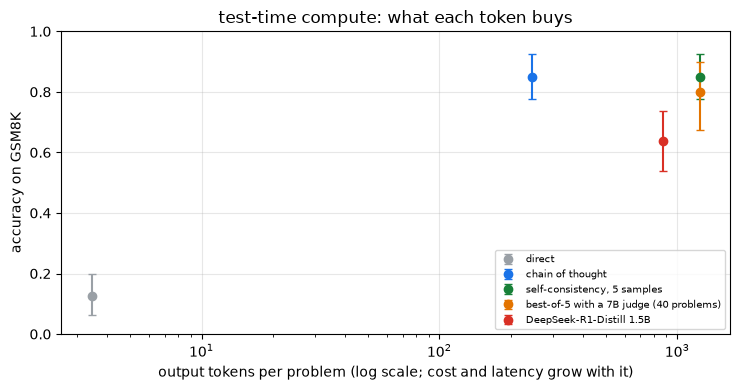

In [7]:
print(f"{'strategy':42s} {'accuracy [95% CI]':>24s} {'output tokens':>14s} {'seconds':>8s}")
for name, r in RES.items():
    m, lo, hi = bootstrap_ci(r["ok"])
    print(f"{name:42s} {m:7.1%} [{lo:.1%}, {hi:.1%}] {r['tokens']:14.0f} {r['secs']:8.2f}")
fig, ax = plt.subplots(figsize=(7.5, 4))
colors = ["#9aa0a6", "#1a73e8", "#188038", "#e37400", "#d93025"]
for (name, r), c in zip(RES.items(), colors):
    m, lo, hi = bootstrap_ci(r["ok"])
    ax.errorbar(r["tokens"], m, yerr=[[m - lo], [hi - m]], fmt="o", color=c, capsize=3, label=name)
ax.set_xscale("log"); ax.set_xlabel("output tokens per problem (log scale; cost and latency grow with it)")
ax.set_ylabel("accuracy on GSM8K"); ax.set_ylim(0, 1); ax.grid(alpha=.3); ax.legend(fontsize=7, loc="lower right")
ax.set_title("test-time compute: what each token buys"); plt.tight_layout(); plt.show()

**What the numbers say.** On a log axis of tokens, the picture is a curve of diminishing returns:

- the first 243 tokens of reasoning bought **72.5 points** (12.5 % → 85.0 %);
- the next ~1,000 tokens of self-consistency bought nothing measurable this time (85.0 %);
- the verifier spent the same tokens plus 12 s of judging and lost 5 points;
- the reasoning model spent 870 tokens for less than plain chain of thought.

Test-time compute is real, but each step must be measured: the cheapest strategy that meets the quality target wins, and here that is one chain of thought; voting is worth trying only where a few points justify 5× the cost, and only after measuring that it gives them.

## 6. Comparative evaluation: a ranking from pairwise outcomes, and a judge's position bias

**Bradley-Terry.** On every problem, each pair of strategies "plays a match": if one is right and the other wrong, the right one wins (ties are skipped). We fit Bradley-Terry scores with the standard minorization-maximization updates and bootstrap the problems for intervals. Then the **judge's bias**: on 30 problems, the judge compares the greedy chain-of-thought solution with the R1 solution, once in each order. A consistent judge picks the same solution both times.

In [8]:
NAMES = ["direct", "chain of thought", "self-consistency, 5 samples", "DeepSeek-R1-Distill 1.5B"]
OK = np.stack([RES[n]["ok"] for n in NAMES])                       # (strategies, problems)
def bradley_terry(ok, iters=200):
    S = len(ok); W = np.zeros((S, S))
    for i in range(S):
        for j in range(S):
            if i != j: W[i, j] = ((ok[i] == 1) & (ok[j] == 0)).sum()
    p = np.ones(S)
    for _ in range(iters):
        for i in range(S):
            den = sum((W[i, j] + W[j, i]) / (p[i] + p[j]) for j in range(S) if j != i)
            p[i] = (W[i].sum() + 0.5) / (den + 1e-9)                  # +0.5 keeps a strategy that never wins finite
        p /= np.exp(np.log(p).mean())
    return np.log(p)
beta = bradley_terry(OK)
rng = np.random.default_rng(0)
boot = np.array([bradley_terry(OK[:, rng.integers(0, N_PROB, N_PROB)]) for _ in range(300)])
for i in np.argsort(-beta):
    lo, hi = np.percentile(boot[:, i], [2.5, 97.5])
    print(f"{NAMES[i]:30s} Bradley-Terry score {beta[i]:+.2f} [{lo:+.2f}, {hi:+.2f}]")
i, j = NAMES.index("chain of thought"), NAMES.index("DeepSeek-R1-Distill 1.5B")
print(f"P(chain of thought beats R1-Distill on a problem where they differ) = {1 / (1 + np.exp(beta[j] - beta[i])):.0%}")

from typing import Literal
class Choice(BaseModel):
    reasoning: str = Field(description="at most two short sentences, plain text, no LaTeX")
    better: Literal["A", "B"]
pair_judge = get_judge_llm(num_predict=600).with_structured_output(Choice, method="json_schema", include_raw=True)
def ask(q, a, b):
    out = pair_judge.invoke([("system", "You compare two solutions to a math word problem and pick the one with the correct final answer and sound reasoning. Keep the reasoning to two short sentences."),
                             ("user", f"Problem: {q}\n\nSolution A:\n{a[-1200:]}\n\nSolution B:\n{b[-1200:]}")])
    return out["parsed"].better if out["parsed"] is not None else "?"     # '?' = unparsed verdict
N_J = 30
picks = []
for p in range(N_J):
    a, b = cot_texts[p], R1_TEXTS[p].split("</think>")[-1]
    first = ask(QUESTIONS[p], a, b); second = ask(QUESTIONS[p], b, a)
    picks.append(("cot" if first == "A" else "r1", "cot" if second == "B" else "r1", first, second, p))
picks = [x for x in picks if "?" not in (x[2], x[3])]          # drop pairs where a verdict could not be parsed
consistent = np.mean([x[0] == x[1] for x in picks])
says_a = np.mean([x[2] == "A" for x in picks] + [x[3] == "A" for x in picks])
right_pick = []
for x1, x2, _, _, p in picks:
    c_ok, r_ok = RES["chain of thought"]["ok"][p], RES["DeepSeek-R1-Distill 1.5B"]["ok"][p]
    if x1 == x2 and c_ok != r_ok:
        right_pick.append((x1 == "cot") == bool(c_ok))
print(f"\n{len(picks)} of {N_J} pairs judged in both orders | consistency when the order is swapped: {consistent:.0%} | share of verdicts for position A: {says_a:.0%}")
print(f"when consistent and exactly one solution is right, the judge picked the right one {np.mean(right_pick):.0%} of {len(right_pick)} times")

self-consistency, 5 samples    Bradley-Terry score +2.06 [+1.50, +3.44]
chain of thought               Bradley-Terry score +1.58 [+0.60, +3.26]
DeepSeek-R1-Distill 1.5B       Bradley-Terry score -0.25 [-1.09, +0.38]
direct                         Bradley-Terry score -3.38 [-4.96, -2.65]
P(chain of thought beats R1-Distill on a problem where they differ) = 86%



30 of 30 pairs judged in both orders | consistency when the order is swapped: 47% | share of verdicts for position A: 53%
when consistent and exactly one solution is right, the judge picked the right one 89% of 9 times


**What the numbers say.**

- **The Bradley-Terry ranking** orders the strategies as self-consistency (+2.06 [+1.50, +3.44]), chain of thought (+1.58 [+0.60, +3.26]), R1-Distill (−0.25) and direct (−3.38). The top two intervals overlap, which agrees with section 2 (they tie on accuracy); the rest are clearly separated. The scores read as probabilities: on a problem where they differ, chain of thought beats R1-Distill 86 % of the time. Ranking from pairwise outcomes is how Chatbot Arena turns millions of votes into a leaderboard, and it works the same with right/wrong outcomes.
- **The pairwise LLM judge is the cautionary tale.** All 30 pairs were judged in both orders, and the judge gave the *same* answer only **47 %** of the time; flipping the order flipped its verdict most of the time. It did not prefer one position overall (53 % of verdicts for A), so this is not a simple position bias: on these pairs its choice is mostly noise. When it was consistent and exactly one solution was right, it chose the right one 89 % of the time, but that was only 9 cases.

Judging every pair in both orders, and counting only consistent verdicts, is the minimum standard for pairwise LLM evaluation, and here it shows the judge should not be trusted on this task without a stronger model or ground-truth checks.

## 7. Reasoning effort on an API model

Sections 1–5 controlled reasoning from the outside: the prompt, the number of samples, the token limit. Current reasoning models expose the same trade-off as a **parameter**.
- **Anthropic's `effort`** (`low` … `max`) sets how hard Claude thinks before answering; at `medium` and above the model writes a hidden reasoning block first.
- **OpenAI's `reasoning_effort`** and **Gemini's thinking budget** play the same role.

The model decides how much to think within that setting (adaptive thinking), and the thinking tokens are billed as output tokens.

The same 80 problems with **Claude Haiku 5.5**, Anthropic's small and fast model, in six settings:
1. **direct**: "final number only", thinking off. The API version of section 1's direct answer.
2. **no thinking**: the chain-of-thought prompt, thinking off.
3. **`effort` low, medium, high and max**: the same prompt, adaptive thinking on.

This section needs an `ANTHROPIC_API_KEY` in `.env` (the whole section costs a few cents) and is skipped without one.

In [9]:
from concurrent.futures import ThreadPoolExecutor
from dotenv import load_dotenv
load_dotenv(os.path.join(ROOT, ".env"))
EFFORT_RES = {}
API_MODEL = "claude-haiku-5-5"
PRICE_IN, PRICE_OUT = 0.10, 0.50          # US$ per million input / output tokens (Anthropic's list price, November 2026)
if os.environ.get("ANTHROPIC_API_KEY"):
    import anthropic
    client = anthropic.Anthropic(max_retries=4)
    SETTINGS = {
        "direct, thinking off": dict(prompt=DIRECT, output_config={"effort": "low"}, thinking={"type": "disabled"}),
        "chain of thought, thinking off": dict(prompt=COT, output_config={"effort": "low"}, thinking={"type": "disabled"}),
        "effort low": dict(prompt=COT, output_config={"effort": "low"}),
        "effort medium": dict(prompt=COT, output_config={"effort": "medium"}),
        "effort high": dict(prompt=COT, output_config={"effort": "high"}),
        "effort max": dict(prompt=COT, output_config={"effort": "max"}),
    }
    def ask_claude(q, s):
        t0 = time.time()
        kw = {k: v for k, v in s.items() if k != "prompt"}
        r = client.messages.create(model=API_MODEL, max_tokens=16000, system=s["prompt"], messages=[{"role": "user", "content": q}], **kw)
        text = "".join(b.text for b in r.content if b.type == "text")
        thought = any(b.type == "thinking" for b in r.content)
        return text, r.usage.input_tokens, r.usage.output_tokens, time.time() - t0, thought, r.stop_reason
    for name, s in SETTINGS.items():
        with ThreadPoolExecutor(8) as pool:
            outs = list(pool.map(lambda q: ask_claude(q, s), QUESTIONS))
        ok = np.array([correct(final_number(o[0]), g) for o, g in zip(outs, GOLD)], dtype=float)
        tin, tout = np.array([o[1] for o in outs]), np.array([o[2] for o in outs])
        EFFORT_RES[name] = dict(ok=ok, tokens=float(tout.mean()), p90=float(np.percentile(tout, 90)), secs=float(np.mean([o[3] for o in outs])),
                                thought=float(np.mean([o[4] for o in outs])), cut=int(sum(o[5] == "max_tokens" for o in outs)),
                                cost=float((tin.sum() * PRICE_IN + tout.sum() * PRICE_OUT) / 1e6 / len(outs)))
        m, lo, hi = bootstrap_ci(ok); r = EFFORT_RES[name]
        print(f"{name:32s} accuracy {m:6.1%} [{lo:.1%}, {hi:.1%}] | output tokens {r['tokens']:6.0f} (p90 {r['p90']:5.0f}) "
              f"| thinking block in {r['thought']:4.0%} | {r['secs']:4.1f} s | US$ {r['cost']:.5f} per problem | cut off: {r['cut']}")
else:
    print("no ANTHROPIC_API_KEY in .env: section skipped")

direct, thinking off             accuracy  78.8% [68.8%, 87.5%] | output tokens     56 (p90   126) | thinking block in   0% |  1.1 s | US$ 0.00004 per problem | cut off: 0


chain of thought, thinking off   accuracy  95.0% [90.0%, 98.8%] | output tokens    162 (p90   234) | thinking block in   0% |  1.5 s | US$ 0.00009 per problem | cut off: 0


effort low                       accuracy  92.5% [86.2%, 97.5%] | output tokens    174 (p90   257) | thinking block in   4% |  1.7 s | US$ 0.00010 per problem | cut off: 0


effort medium                    accuracy  96.2% [91.2%, 100.0%] | output tokens    281 (p90   453) | thinking block in  54% |  1.9 s | US$ 0.00015 per problem | cut off: 0


effort high                      accuracy  96.2% [91.2%, 100.0%] | output tokens    306 (p90   484) | thinking block in  98% |  2.2 s | US$ 0.00017 per problem | cut off: 0


effort max                       accuracy  98.8% [96.2%, 100.0%] | output tokens    674 (p90   868) | thinking block in 100% |  3.4 s | US$ 0.00035 per problem | cut off: 0


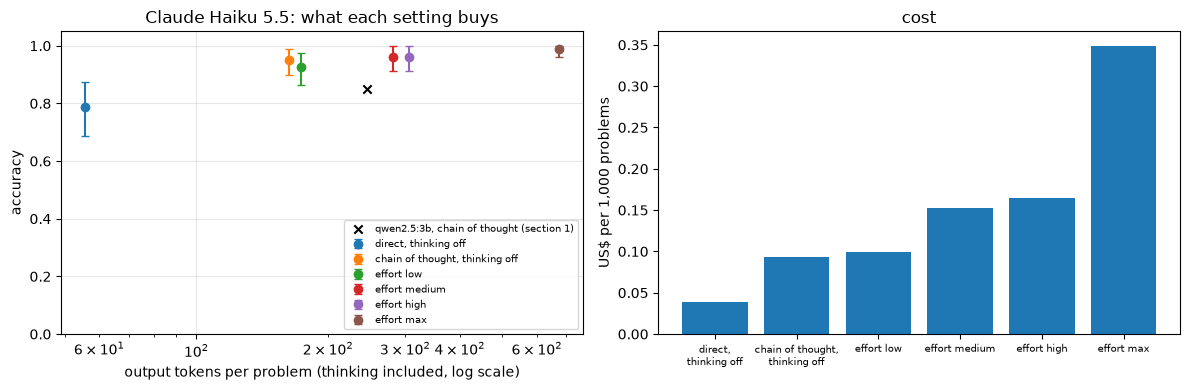

In [10]:
if EFFORT_RES:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    names = list(EFFORT_RES)
    for i, n in enumerate(names):
        r = EFFORT_RES[n]; m, lo, hi = bootstrap_ci(r["ok"])
        ax[0].errorbar(r["tokens"], m, yerr=[[m - lo], [hi - m]], fmt="o", capsize=3, label=n)
    q3 = RES["chain of thought"]
    ax[0].scatter([q3["tokens"]], [q3["ok"].mean()], marker="x", color="k", label="qwen2.5:3b, chain of thought (section 1)")
    ax[0].set_xscale("log"); ax[0].set_xlabel("output tokens per problem (thinking included, log scale)"); ax[0].set_ylabel("accuracy")
    ax[0].set_ylim(0, 1.05); ax[0].grid(alpha=.3); ax[0].legend(fontsize=7, loc="lower right"); ax[0].set_title("Claude Haiku 5.5: what each setting buys")
    ax[1].bar(range(len(names)), [EFFORT_RES[n]["cost"] * 1000 for n in names], color="tab:blue")
    ax[1].set_xticks(range(len(names)), [n.replace(", ", ",\n") for n in names], fontsize=7)
    ax[1].set_ylabel("US$ per 1,000 problems"); ax[1].set_title("cost")
    plt.tight_layout(); plt.show()

**What the numbers say.**

- **The big model barely needs the help on GSM8K.** The 3B model went from 12.5 % to 85.0 % with a chain of thought; Haiku 5.5 already gets **78.8 %** when told to give the number only. It did not quite obey: it averaged 56 output tokens, not 3, so some working leaked into the answer anyway.
- **Writing the steps is still the largest lever:** the chain-of-thought prompt with thinking off reaches **95.0 %** with 162 tokens, in 1.5 s.
- **`effort` controls how often the model thinks, not only how long.** A hidden thinking block appeared in 4 % of answers at `low`, 54 % at `medium` (the default), 98 % at `high` and 100 % at `max`. That is adaptive thinking at work: at lower settings the model skips thinking on problems it judges easy.
- **Accuracy moves within noise until `max`:** low 92.5 %, medium and high 96.2 %, max **98.8 %** (1 miss in 80). The intervals all overlap; on 80 problems, none of these settings is measurably better than chain of thought with thinking off.
- **Cost and latency grow with the setting:** 174 output tokens at `low` and 674 at `max` (4×), 1.7 s against 3.4 s. Even `max` costs US$0.35 per 1,000 problems at Haiku's price, and no answer hit the 16,000-token limit.

So on an easy benchmark for this model, `effort` is mainly a cost and latency dial: the default is already near the ceiling, and `max` buys the last couple of points at 2.4 times the tokens of `medium`. The setting pays off on harder tasks (long agentic work, hard proofs, difficult code), and the way to find out is the same as everywhere in this notebook: measure on your own task.

## Results

| strategy (qwen2.5:3b unless noted, 80 GSM8K problems) | accuracy [95% CI] | output tokens per problem | seconds per problem |
|---|---|---|---|
| direct answer | 12.5 % [6.2, 20.0] | 3 | 0.18 |
| chain of thought (greedy) | **85.0 %** [77.5, 92.5] | 246 | 3.79 |
| self-consistency, 5 samples (maj@5) | 85.0 % [77.5, 92.5]; pass@5 92.5 % | 1,241 | 18.42 |
| best-of-5 with a 7B judge (first 40) | 80.0 % (majority 85.0 %, pass@5 92.5 %) | 1,241 + judging | 30.71 |
| DeepSeek-R1-Distill 1.5B | 63.7 % [53.8, 73.8]; 16 hit the token limit | 870 | 6.93 |
| Bradley-Terry ranking | self-consistency ≈ chain of thought > R1-Distill > direct | | |
| pairwise LLM judge, both orders | consistent on only 47 % of 30 pairs | | |
| **Claude Haiku 5.5**, chain of thought, thinking off | 95.0 % [90.0, 98.8] | 162 | 1.5 |
| Claude Haiku 5.5, `effort` medium (default) | 96.2 % [91.2, 100] | 281 | 1.9 |
| Claude Haiku 5.5, `effort` max | **98.8 %** [96.2, 100] | 674 | 3.4 |

What this establishes: reasoning tokens are the single largest lever (+72.5 points), parallel sampling did not add measurable accuracy here at 5× the cost, an LLM verifier helps only if it discriminates better than a vote (this one did not), a small distilled reasoning model can lose to good prompting of a larger instruct model, and on a frontier API model `effort` is a cost dial: every setting from no thinking to `max` lands within a few points on GSM8K, for 1.5–3.4 s and US$0.09–0.35 per 1,000 problems.

## In production

**Choosing a strategy.**
- Start with chain of thought, or a reasoning model with a capped thinking budget, and measure accuracy *and* tokens on your own task.
- On an API model with an effort setting, start at the default and move down while accuracy holds on your eval set; raise it only for the tasks that measurably need it. Here, `effort` high cost more than medium for the same 96.2 %.
- Add self-consistency only where the extra accuracy is worth $k$× the cost, typically offline jobs or high-value queries, and use `k` between 3 and 8.
- Use best-of-N only with a verifier that has been shown to discriminate: unit tests for code, a calculator or solver for math, a schema validator for extraction, or a trained reward model.

**Serving reasoning models.**
- Set explicit limits: `max_tokens`, or a thinking budget where the provider exposes one.
- Stream the answer, and watch the share of responses that hit the limit. Here 16 of 80 did, which is a quality bug as well as a cost bug.
- Parse the final answer robustly (here: the last number after `</think>`) and count extraction failures as their own metric.
- Price by output tokens, which are the slow and expensive ones.

**Evaluating with judges.**
- Judge every pair in both orders, report consistency, and discard inconsistent verdicts.
- Validate the judge against ground truth on a sample before trusting it (notebooks 18 and 28).
- Bound the judge's own reasoning, so verdicts are not cut off.
- Rank with Bradley-Terry and bootstrap intervals, never from a single average.

**What to monitor.**
- Tokens per request and their tail: reasoning models have long tails.
- The rate of truncated or unparseable answers.
- Accuracy against the per-task target, and the latency budget.

**Failure modes.**
- Overthinking (long, looping reasoning that never answers).
- Unfaithful reasoning that looks right but did not produce the answer.
- Verifiers that reward fluency over correctness.
- Inconsistent pairwise judges.
- Answer-extraction bugs that silently change the score.

**Next:** `16_agents_tools_structured_output.ipynb` (tools, function calling and structured output), or notebook 25 to see reasoning inside agents.